In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import f1_score, recall_score
from src.data import load_data
from src.config import RANDOM_STATE, CV_DIR, FIG_DIR
from src.pipelines import get_final

# Tải dữ liệu train và thiết lập chia 5 fold phân tầng
X_train, _, y_train, _, labels = load_data()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cac_ty_le = [0.1, 0.25, 0.5, 0.75, 1.0]
danh_sach_nhanh = list(range(12))
rows = []

for ty_le in cac_ty_le:
    for k, (tr, va) in enumerate(cv.split(X_train, y_train)):
        # Lấy dữ liệu train và validation của fold hiện tại
        X_fold_tr = X_train.iloc[tr]
        y_fold_tr = y_train.iloc[tr]
        X_va = X_train.iloc[va]
        y_va = y_train.iloc[va]

        # Nếu tỷ lệ nhỏ hơn 1.0 thì trích một phần dữ liệu train theo tầng nhãn
        if ty_le < 1.0:
            Xtr, X_bo, ytr, y_bo = train_test_split(
                X_fold_tr,
                y_fold_tr,
                train_size=ty_le,
                stratify=y_fold_tr,
                random_state=RANDOM_STATE,
            )
        else:
            Xtr = X_fold_tr
            ytr = y_fold_tr

        # Huấn luyện mô hình trên tập train con và dự đoán trên tập validation của fold
        model = get_final()
        model.fit(Xtr, ytr)
        pred = model.predict(X_va)

        # Tính recall từng lớp và macro-f1 trên tập validation
        rec = recall_score(
            y_va,
            pred,
            average=None,
            labels=danh_sach_nhanh,
            zero_division=0,
        )
        macro_f1_val = f1_score(
            y_va,
            pred,
            average="macro",
            labels=danh_sach_nhanh,
            zero_division=0,
        )

        thong_tin = {
            "ty_le": ty_le,
            "fold": k,
            "so_mau_train": len(ytr),
            "macro_f1": macro_f1_val,
            "recall_c4": rec[4],
            "recall_c5": rec[5],
            "recall_c11": rec[11],
        }
        rows.append(thong_tin)

    print("xong ty le", ty_le)

# Lưu toàn bộ kết quả từng fold ra file CSV
d = pd.DataFrame(rows)
d.to_csv(CV_DIR / "learning_curve.csv", index=False)

# Tổng hợp trung bình và độ lệch chuẩn theo từng tỷ lệ dữ liệu train
cac_cot_chi_tieu = ["so_mau_train", "macro_f1", "recall_c4", "recall_c5", "recall_c11"]
tb = d.groupby("ty_le")[cac_cot_chi_tieu].agg(["mean", "std"])
tb = tb.round(4)

tb

xong ty le 0.1
xong ty le 0.25
xong ty le 0.5
xong ty le 0.75
xong ty le 1.0


so_mau_train         macro_f1         recall_c4         recall_c5  \
              mean     std     mean     std      mean     std      mean   
ty_le                                                                     
0.10        7546.6  0.5477   0.9258  0.0451    0.4600  0.3722      0.82   
0.25       18867.0  0.0000   0.9552  0.0157    0.7267  0.1441      0.82   
0.50       37734.6  0.5477   0.9577  0.0205    0.6933  0.1321      0.82   
0.75       56601.6  0.5477   0.9643  0.0105    0.7600  0.1461      0.82   
1.00       75469.6  0.5477   0.9633  0.0127    0.7267  0.1441      0.82   

              recall_c11          
          std       mean     std  
ty_le                             
0.10   0.1037     0.8400  0.0717  
0.25   0.1037     0.8971  0.0848  
0.50   0.1037     0.9486  0.0711  
0.75   0.1037     0.9543  0.0383  
1.00   0.1037     0.9657  0.0469

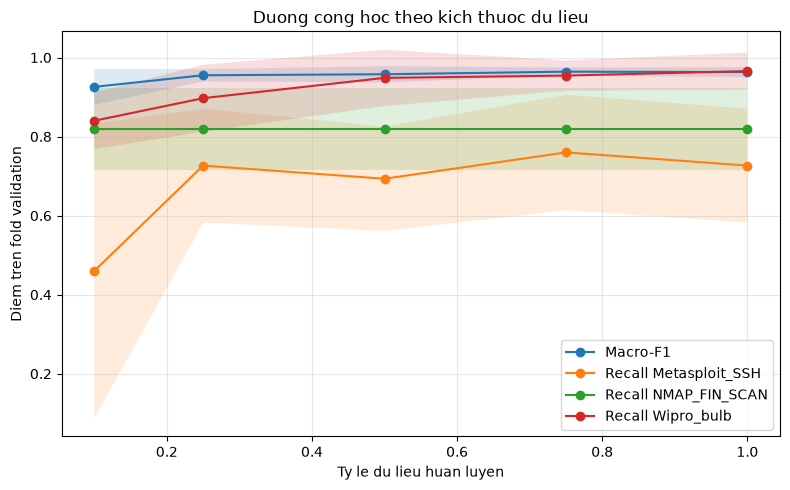

In [2]:
# Gom nhóm kết quả theo tỷ lệ dữ liệu huấn luyện
g = d.groupby("ty_le")

fig, ax = plt.subplots(figsize=(8, 5))

# Danh sách các chỉ tiêu cần vẽ trên cùng một biểu đồ
cac_duong = [
    ("macro_f1", "Macro-F1"),
    ("recall_c4", "Recall Metasploit_SSH"),
    ("recall_c5", "Recall NMAP_FIN_SCAN"),
    ("recall_c11", "Recall Wipro_bulb"),
]

for cot, nhan in cac_duong:
    # Tính giá trị trung bình và độ lệch chuẩn qua các fold cho từng tỷ lệ
    mean_vals = g[cot].mean()
    std_vals = g[cot].std()

    ty_le_truc_x = mean_vals.index
    diem_tb = mean_vals.values
    can_duoi = diem_tb - std_vals.values
    can_tren = diem_tb + std_vals.values

    # Vẽ đường trung bình có điểm đánh dấu và vùng bóng thể hiện độ lệch chuẩn
    ax.plot(ty_le_truc_x, diem_tb, marker="o", linestyle="-", label=nhan)
    ax.fill_between(ty_le_truc_x, can_duoi, can_tren, alpha=0.15)

ax.set_xlabel("Ty le du lieu huan luyen")
ax.set_ylabel("Diem tren fold validation")
ax.set_title("Duong cong hoc theo kich thuoc du lieu")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "learning_curve.png", dpi=300, bbox_inches="tight")
plt.show()